# M4.3 · Black-Litterman 模型

> 经典均值-方差优化对期望收益极其敏感，输入微小变化就产生极端角点解，且难以融入投资者的主观判断。
> Black-Litterman（1990，高盛）用**逆优化**从市场组合反推均衡收益，再用贝叶斯方式融合主观观点，得到稳定、可解释的配置。

## 一、核心思想：从市场共识出发

1. **逆优化**：假设当前市场组合是均衡的，反推其隐含的均衡收益
$$\pi=\delta\Sigma w_{\text{mkt}}$$
其中 $\delta$ 为风险厌恶系数，$w_{\text{mkt}}$ 为市场权重；
2. **表达观点**：用矩阵 $P$（观点组合）、$Q$（观点收益）、$\Omega$（观点不确定性/信心）描述主观判断；
3. **贝叶斯融合**：把均衡收益当先验、观点当观测，得后验收益
$$E[R]=\left[(\tau\Sigma)^{-1}+P^\top\Omega^{-1}P\right]^{-1}
\left[(\tau\Sigma)^{-1}\pi+P^\top\Omega^{-1}Q\right]$$
4. 用后验收益做均值-方差优化得到权重。$\tau$ 为先验置信度（通常 0.025~0.05）。


## 二、准备年化协方差与均衡收益

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np, pandas as pd
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from port_lab2 import covariance as covm, black_litterman as bl
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$close'], start_time='2018-01-01', freq='day')
cl = raw['$close'].unstack('instrument')
ret = cl.pct_change(fill_method=None)
sub = ret.iloc[-750:, :50].dropna(axis=1)
Sann = covm.sample_cov(sub, ann=242)
n = Sann.shape[0]
w_mkt = np.ones(n)/n            # 教学用等权代理市场权重（实务用市值权重）
delta = 2.5
pi = bl.equilibrium_returns(Sann, w_mkt, delta)
print('年化协方差形状:', Sann.shape)
print('均衡收益: 均值=%.4f 范围[%.4f, %.4f]' % (pi.mean(), pi.min(), pi.max()))

[1704:MainThread](2026-11-05 14:07:51,995) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[1704:MainThread](2026-11-05 14:07:53,912) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[1704:MainThread](2026-11-05 14:07:53,913) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


年化协方差形状: (50, 50)
均衡收益: 均值=0.0673 范围[0.0233, 0.1118]


## 三、构造主观观点

设两个观点：
- **观点1（相对）**：资产 0 跑赢资产 1，超额收益 5%；
- **观点2（绝对）**：资产 2 的年化收益为 8%。

$\Omega$ 默认取 $\operatorname{diag}(\tau P\Sigma P^\top)$，观点信心越低、$\Omega$ 越大，后验越靠近均衡。

In [2]:
P = np.zeros((2, n))
P[0, 0] = 1.0; P[0, 1] = -1.0
P[1, 2] = 1.0
Q = np.array([0.05, 0.08])
post = bl.bl_posterior(Sann, pi, P, Q, tau=0.05)
print('观点矩阵 P 非零列:', [(i, np.nonzero(P[:, i])[0].tolist())
                            for i in range(n) if P[:, i].any()])
print('观点不确定 Omega 对角:', np.round(np.diag(post['omega'].values), 5))
print('均衡 vs 后验 收益:')
cmp = pd.DataFrame({'均衡收益': pi, '后验收益': post['er']})
print(cmp.iloc[:5].round(4).to_string())

观点矩阵 P 非零列: [(0, [0]), (1, [0]), (2, [1])]
观点不确定 Omega 对角: [0.00305 0.00667]
均衡 vs 后验 收益:
            均衡收益    后验收益
SH600000  0.0313  0.0520
SH600009  0.0559  0.0393
SH600010  0.0881  0.0787
SH600011  0.0519  0.0520
SH600015  0.0329  0.0433


## 四、后验组合权重

In [3]:
w_bl = bl.bl_weights(Sann, post['er'], delta, long_only=True)
w_eq = pd.Series(w_mkt, index=Sann.index)
print('BL 权重: 和=%.4f 非零只数=%d 最大=%.4f'
      % (w_bl.sum(), (w_bl > 1e-6).sum(), w_bl.max()))
print('BL 组合年化波动 = %.4f' % np.sqrt(w_bl @ Sann.values @ w_bl))
print('等权组合年化波动 = %.4f' % np.sqrt(w_eq @ Sann.values @ w_eq))

BL 权重: 和=1.0000 非零只数=46 最大=0.2524
BL 组合年化波动 = 0.1563
等权组合年化波动 = 0.1640


## 五、观点信心的影响：缩放 Omega

In [4]:
rows = []
for scale in [0.25, 1.0, 4.0]:
    om = post['omega'].values * scale
    p2 = bl.bl_posterior(Sann, pi, P, Q, tau=0.05, omega=om)
    rows.append({'Omega倍数': scale,
                 '资产0后验收益': p2['er'].iloc[0],
                 '资产1后验收益': p2['er'].iloc[1]})
print(pd.DataFrame(rows).round(4).to_string(index=False))
print('（Omega 越大=越没信心，后验越向均衡收敛）')

 Omega倍数  资产0后验收益  资产1后验收益
    0.25   0.0650   0.0301
    1.00   0.0520   0.0393
    4.00   0.0395   0.0491
（Omega 越大=越没信心，后验越向均衡收敛）


## 六、图表

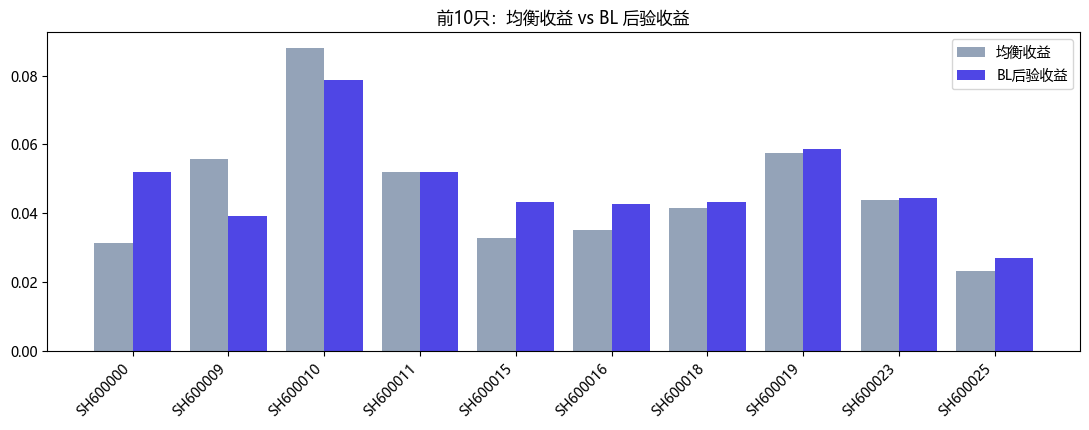

In [5]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
show = np.arange(10)
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.bar(show-0.2, pi.values[:10], 0.4, label='均衡收益', color='#94a3b8')
ax.bar(show+0.2, post['er'].values[:10], 0.4, label='BL后验收益', color='#4f46e5')
ax.set_xticks(show); ax.set_xticklabels(Sann.index[:10], rotation=45, ha='right')
ax.set_title('前10只：均衡收益 vs BL 后验收益'); ax.legend()
plt.tight_layout(); plt.show()

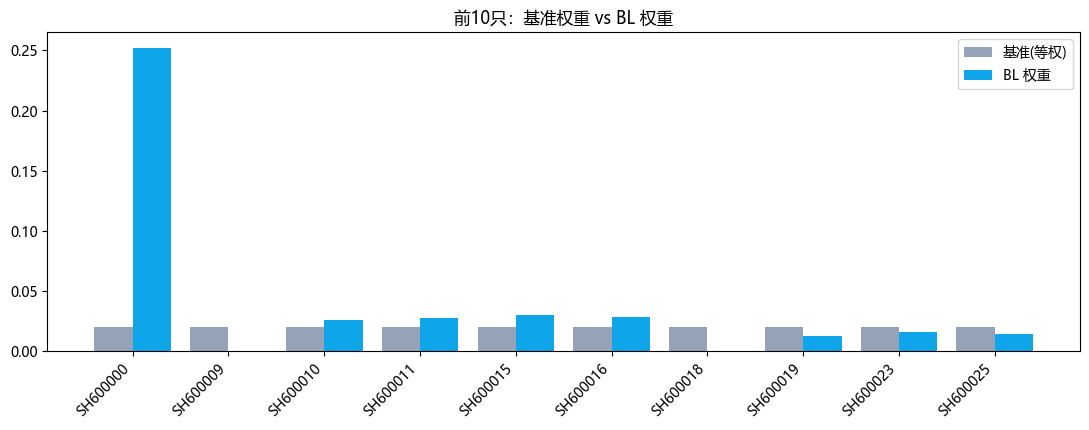

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.bar(show-0.2, w_eq.values[:10], 0.4, label='基准(等权)', color='#94a3b8')
ax.bar(show+0.2, w_bl.values[:10], 0.4, label='BL 权重', color='#0ea5e9')
ax.set_xticks(show); ax.set_xticklabels(Sann.index[:10], rotation=45, ha='right')
ax.set_title('前10只：基准权重 vs BL 权重'); ax.legend()
plt.tight_layout(); plt.show()

## 七、结论与适用条件

- BL 以**逆优化的均衡收益**为起点，避免了主观猜测期望收益导致的不稳定；
- 观点通过 $P,Q,\Omega$ 显式表达，信心可量化，后验在共识与观点间平滑加权；
- 输出权重比朴素均值-方差更分散、更稳定，适合有明确宏观/行业观点的主动配置与 FOF；
- 局限：结果仍依赖协方差质量与 $\tau,\Omega$ 的设定，观点本身可能错误。

## 八、面试要点

- **BL 解决什么问题？** 均值-方差对期望收益敏感、角点解、难融主观观点；
- **均衡收益怎么来的？** 逆优化 $\pi=\delta\Sigma w_{\text{mkt}}$，假设市场组合已均衡；
- **$\Omega$ 和 $\tau$ 的作用？** $\Omega$ 衡量观点不确定性（信心），$\tau$ 衡量先验置信度；
- **观点信心如何影响结果？** $\Omega$ 越大越没信心，后验越靠近均衡；
- **BL 后验公式的贝叶斯解释？** 均衡为先验、观点为带噪声观测，后验为两者精度加权。

## 动手练习
1. 用逆优化计算均衡收益 $\pi$；
2. 构造一个相对观点和一个绝对观点，计算后验收益与权重；
3. 缩放 $\Omega$，观察后验收益如何随观点信心变化。

---
下一节 M4.4 进入风险平价与 HRP。